# Milestone 1: EDA and Problem Formulation

FPA-FOD 7th edition: 2.66 M US wildfires from 1992 to 2024.

Plan: check data quality, look at when / where / how big fires are, then use that to pick one supervised and one unsupervised problem.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import NearestNeighbors

%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
SEED = 281


def find_data_dir(name='wildfire_7th_edition_data'):
    # search this folder and its parents so the notebook works from anywhere in the repo
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / name / 'Data').is_dir():
            return d / name / 'Data'
    raise FileNotFoundError(f'{name}/Data not found, run the starter download cell first')


DB_PATH = find_data_dir() / 'FPA_FOD_20260615.sqlite'

## Load the data

I load the full table instead of using the starter's `LIMIT 500000 ... WHERE CONT_DATE IS NOT NULL`, since both filters bias the sample (see section 1).

In [2]:
cols = ['FIRE_YEAR', 'DISCOVERY_DATE', 'DISCOVERY_DOY', 'DISCOVERY_TIME', 'CONT_DATE',
        'FIRE_SIZE', 'FIRE_SIZE_CLASS', 'LATITUDE', 'LONGITUDE', 'STATE', 'OWNER_DESCR',
        'NWCG_REPORTING_AGENCY', 'SOURCE_SYSTEM_TYPE', 'NWCG_CAUSE_CLASSIFICATION', 'NWCG_GENERAL_CAUSE']
query = 'SELECT ' + ', '.join(cols) + ' FROM Fires'
with closing(sqlite3.connect(DB_PATH)) as conn:
    df = pd.read_sql_query(query, conn)

MISSING = 'Missing data/not specified/undetermined'
JD_EPOCH = 2440587.5  # julian day number of 1970-01-01

df['STATE'] = df['STATE'].str.upper()  # Oklahoma shows up as both 'OK' and 'ok'
df['DATE'] = pd.to_datetime(df['DISCOVERY_DATE'] - JD_EPOCH, unit='D')
df['MONTH'] = df['DATE'].dt.month
df['WEEKDAY'] = df['DATE'].dt.dayofweek  # 0 = Monday
hhmm = pd.to_numeric(df['DISCOVERY_TIME'], errors='coerce')
df['DISC_HOUR'] = hhmm // 100
df['DISC_MIN'] = hhmm % 100
df['DURATION_DAYS'] = df['CONT_DATE'] - df['DISCOVERY_DATE']
df['LOG_SIZE'] = np.log10(df['FIRE_SIZE'])
df['CAUSE_CLASS'] = df['NWCG_CAUSE_CLASSIFICATION'].replace({MISSING: 'Missing'})
df['CAUSE_KNOWN'] = df['NWCG_GENERAL_CAUSE'] != MISSING

cat_cols = ['STATE', 'OWNER_DESCR', 'NWCG_REPORTING_AGENCY', 'SOURCE_SYSTEM_TYPE', 'FIRE_SIZE_CLASS',
            'NWCG_CAUSE_CLASSIFICATION', 'NWCG_GENERAL_CAUSE', 'CAUSE_CLASS']
df[cat_cols] = df[cat_cols].astype('category')
print(f'{len(df):,} fires, {df.FIRE_YEAR.min()}-{df.FIRE_YEAR.max()}')
df.head()

2,661,383 fires, 1992-2024


,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,DISCOVERY_TIME,CONT_DATE,FIRE_SIZE,FIRE_SIZE_CLASS,LATITUDE,LONGITUDE,STATE,...,NWCG_GENERAL_CAUSE,DATE,MONTH,WEEKDAY,DISC_HOUR,DISC_MIN,DURATION_DAYS,LOG_SIZE,CAUSE_CLASS,CAUSE_KNOWN
0,2005,2453403.5,33,1300,2453403.5,0.10,A,40.036944,-121.005833,CA,...,Power generation/transmission/distribution,2005-02-02,2,2,13.0,0.0,0.0,-1.00000,Human,True
1,2004,2453137.5,133,0845,2453137.5,0.25,A,38.933056,-120.404444,CA,...,Natural,2004-05-12,5,2,8.0,45.0,0.0,-0.60206,Natural,True
2,2004,2453156.5,152,1921,2453156.5,0.10,A,38.984167,-120.735556,CA,...,Debris and open burning,2004-05-31,5,0,19.0,21.0,0.0,-1.00000,Human,True
3,2004,2453184.5,180,1600,2453189.5,0.10,A,38.559167,-119.913333,CA,...,Natural,2004-06-28,6,0,16.0,0.0,5.0,-1.00000,Natural,True
4,2004,2453184.5,180,1600,2453189.5,0.10,A,38.559167,-119.933056,CA,...,Natural,2004-06-28,6,0,16.0,0.0,5.0,-1.00000,Natural,True


## 1. Data quality

### Missing values by source system

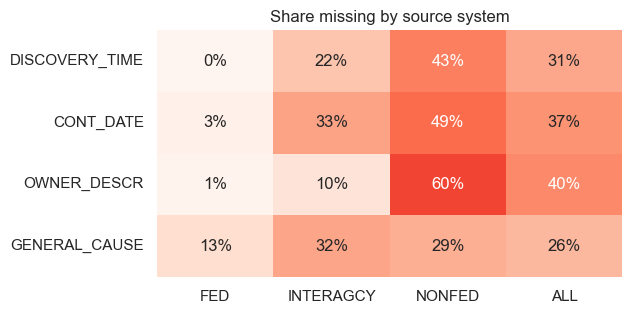

Starter filter (CONT_DATE not null) drops 37.5% of fires
Natural share: 13.4% of all fires vs 18.2% after the filter
FED share:     20.3% of all fires vs 31.5% after the filter


In [3]:
missing = pd.DataFrame({
    'DISCOVERY_TIME': df['DISCOVERY_TIME'].isna(),
    'CONT_DATE': df['CONT_DATE'].isna(),
    'OWNER_DESCR': df['OWNER_DESCR'].eq('MISSING/NOT SPECIFIED'),
    'GENERAL_CAUSE': ~df['CAUSE_KNOWN'],
})
by_source = missing.groupby(df['SOURCE_SYSTEM_TYPE'], observed=True).mean().T
by_source['ALL'] = missing.mean()

plt.figure(figsize=(6, 3.2))
sns.heatmap(by_source, annot=True, fmt='.0%', cmap='Reds', vmin=0, vmax=1, cbar=False)
plt.title('Share missing by source system')
plt.xlabel('')
plt.show()

kept = df['CONT_DATE'].notna()
natural = df['CAUSE_CLASS'].eq('Natural')
fed = df['SOURCE_SYSTEM_TYPE'].eq('FED')
print(f'Starter filter (CONT_DATE not null) drops {1 - kept.mean():.1%} of fires')
print(f'Natural share: {natural.mean():.1%} of all fires vs {natural[kept].mean():.1%} after the filter')
print(f'FED share:     {fed.mean():.1%} of all fires vs {fed[kept].mean():.1%} after the filter')

Federal records are nearly complete, but non-federal records are missing about 43% of discovery times, 49% of containment dates and 60% of land owners. So missing values mostly tell us which agency reported the fire.

Dropping rows without a containment date (like the starter does) removes over a third of the data and shifts it toward federal, lightning-caused fires. I keep all rows.

### Reporting changes over time

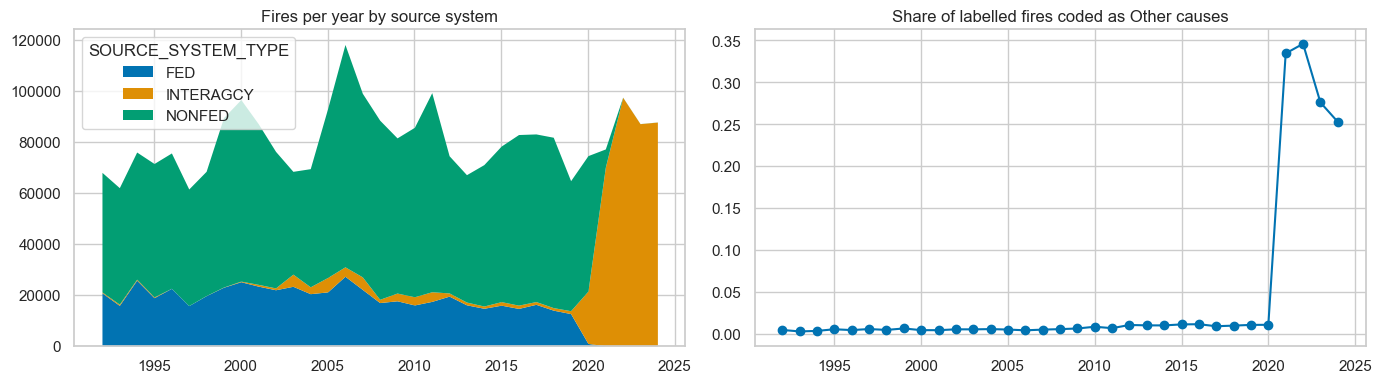

Other causes share by year: {2018: 0.01, 2019: 0.01, 2020: 0.01, 2021: 0.334, 2022: 0.346, 2023: 0.276, 2024: 0.253}


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.crosstab(df['FIRE_YEAR'], df['SOURCE_SYSTEM_TYPE']).plot.area(ax=axes[0], lw=0)
axes[0].set_title('Fires per year by source system')

known = df[df['CAUSE_KNOWN']]
other = known['NWCG_GENERAL_CAUSE'].eq('Other causes').groupby(known['FIRE_YEAR']).mean()
other.plot(ax=axes[1], marker='o')
axes[1].set_title('Share of labelled fires coded as Other causes')
for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
plt.show()
print('Other causes share by year:', other.loc[2018:].round(3).to_dict())

Two reporting changes happen around 2020-2021:
- After 2020 almost every record is labelled INTERAGCY, so SOURCE_SYSTEM_TYPE basically encodes the year. I won't use it as a feature.
- Starting in 2021, about 30% of labelled fires are coded as Other causes (it was about 1% before). This comes from a few states changing how they code causes, not from fires changing. I'll treat Other causes as unlabelled, the same as Missing.

### Rounded coordinates, times and sizes

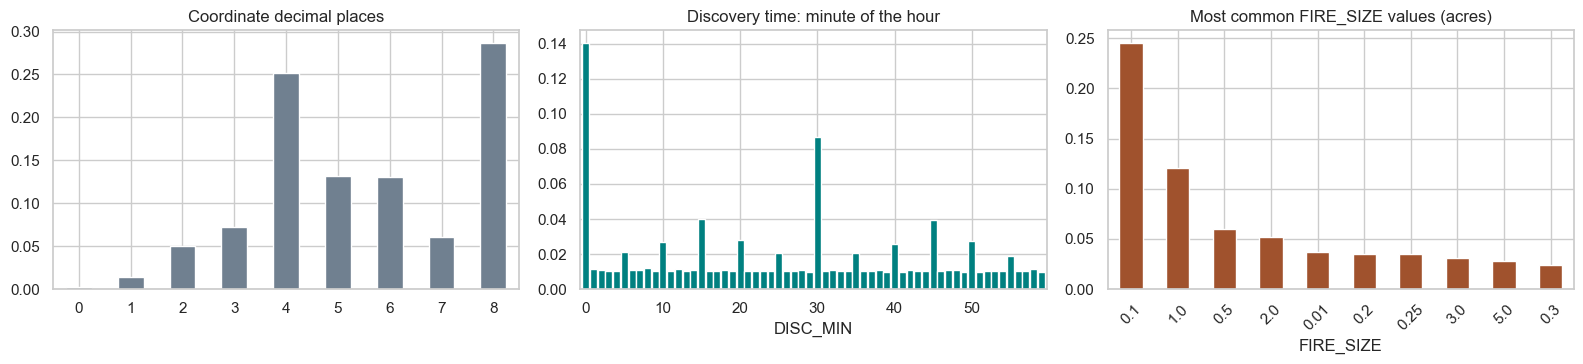

Coordinates with 2 or fewer decimals: 6.7%
Locations shared by 200+ fires: 14 (largest: 571 fires)
Discovery times at :00 or :30: 22.7%
Top 3 size values cover 42.6% of fires


In [5]:
def coord_decimals(x):
    # fewest decimal places that reproduce the stored value
    v = x.to_numpy()
    dec = np.full(len(v), 8)
    for k in range(7, -1, -1):
        dec[np.abs(v - np.round(v, k)) < 1e-9] = k
    return dec


decimals = np.minimum(coord_decimals(df['LATITUDE']), coord_decimals(df['LONGITUDE']))
stack = df.groupby(['LATITUDE', 'LONGITUDE']).size()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
pd.Series(decimals).value_counts(normalize=True).sort_index().plot.bar(ax=axes[0], color='slategray', rot=0)
axes[0].set_title('Coordinate decimal places')
df['DISC_MIN'].value_counts(normalize=True).sort_index().plot.bar(ax=axes[1], color='teal', width=0.9)
axes[1].set_xticks(range(0, 60, 10))
axes[1].set_xticklabels(range(0, 60, 10), rotation=0)
axes[1].set_title('Discovery time: minute of the hour')
df['FIRE_SIZE'].value_counts(normalize=True).head(10).plot.bar(ax=axes[2], color='sienna', rot=45)
axes[2].set_title('Most common FIRE_SIZE values (acres)')
plt.tight_layout()
plt.show()

round_minute = df['DISC_MIN'].isin([0, 30]).sum() / df['DISC_MIN'].notna().sum()
top3_sizes = df['FIRE_SIZE'].value_counts(normalize=True).head(3).sum()
print(f'Coordinates with 2 or fewer decimals: {(decimals <= 2).mean():.1%}')
print(f'Locations shared by 200+ fires: {(stack >= 200).sum()} (largest: {stack.max()} fires)')
print(f'Discovery times at :00 or :30: {round_minute:.1%}')
print(f'Top 3 size values cover {top3_sizes:.1%} of fires')

- About 7% of coordinates have 2 or fewer decimals (roughly 1 km of uncertainty or worse).
- A few exact points hold hundreds of fires each, mostly Puerto Rico records and agency office locations. These are where fires were reported from, not where they started, so I'll de-duplicate them before clustering.
- Times and sizes are rounded by hand: discovery times pile up on :00 and :30, and 0.1, 1 and 0.5 acres account for over 40% of all fires. Fire size is basically ordinal below 1 acre.

## 2. When do fires happen?

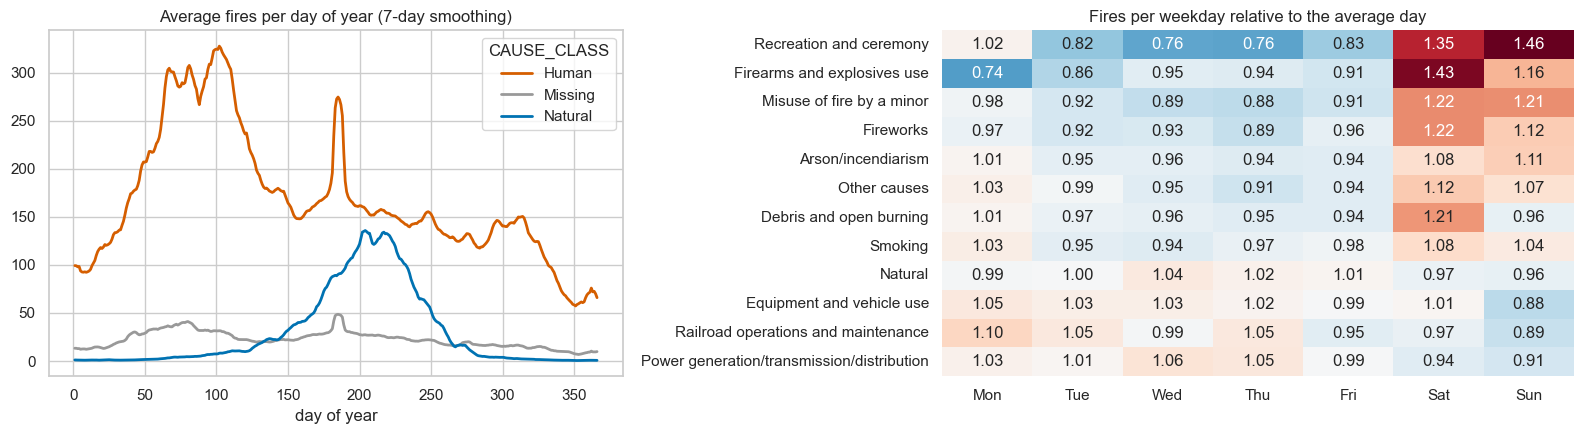

Natural fires in Jun-Aug: 77.8%, human fires in Feb-Apr: 37.3%
Most common discovery hour: {'Human': 14.0, 'Missing': 14.0, 'Natural': 16.0}


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 1.1]})

doy = pd.crosstab(df['DISCOVERY_DOY'], df['CAUSE_CLASS']) / df['FIRE_YEAR'].nunique()
doy.rolling(7, center=True, min_periods=1).mean().plot(ax=axes[0], lw=2, color=['#d55e00', '#999999', '#0072b2'])
axes[0].set_title('Average fires per day of year (7-day smoothing)')
axes[0].set_xlabel('day of year')

wk = pd.crosstab(known['NWCG_GENERAL_CAUSE'].astype(str), known['WEEKDAY'])
wk = wk.div(wk.mean(axis=1), axis=0)
wk.columns = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
wk = wk.loc[wk[['Sat', 'Sun']].mean(axis=1).sort_values(ascending=False).index]
sns.heatmap(wk, annot=True, fmt='.2f', cmap='RdBu_r', center=1, cbar=False, ax=axes[1])
axes[1].set_title('Fires per weekday relative to the average day')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

human = df['CAUSE_CLASS'].eq('Human')
nat_summer = df.loc[natural, 'MONTH'].isin([6, 7, 8]).mean()
human_spring = df.loc[human, 'MONTH'].isin([2, 3, 4]).mean()
peak_hour = df.dropna(subset=['DISC_HOUR']).groupby('CAUSE_CLASS', observed=True)['DISC_HOUR'].agg(lambda s: s.mode().iat[0])
print(f'Natural fires in Jun-Aug: {nat_summer:.1%}, human fires in Feb-Apr: {human_spring:.1%}')
print('Most common discovery hour:', peak_hour.to_dict())

Human and lightning fires peak at different times of year. Human fires peak in early spring (debris burning before green-up) and spike on July 4. Lightning fires peak in July-August with the thunderstorm season, and they're usually discovered a couple of hours later in the day than human fires.

The weekday heatmap shows a clear weekend effect for people-driven causes (recreation, firearms, kids, fireworks, debris burning). Work-related causes drop on Sunday, and lightning is flat across the week. Season, weekday and hour should all help predict cause.

## 3. Where do fires happen?

Hexbin maps of the lower 48 states (plotting 2.6 M points directly is unreadable).

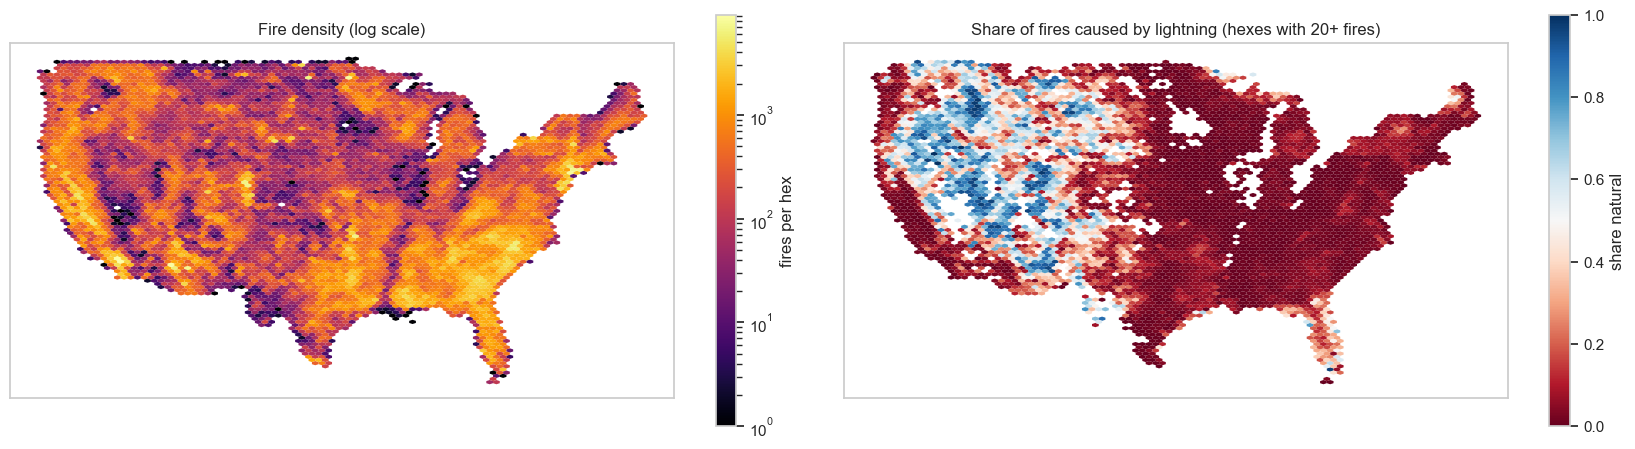

Most acres burned (millions): {'AK': 41.0, 'CA': 25.6, 'ID': 18.1, 'OR': 14.9, 'TX': 14.4}


In [7]:
conus = (df['LONGITUDE'].between(-125, -66) & df['LATITUDE'].between(24, 50)
         & ~df['STATE'].isin(['AK', 'HI', 'PR', 'VI', 'GU']))
c = df.loc[conus, ['LONGITUDE', 'LATITUDE']]
is_natural = natural[conus].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
hb = axes[0].hexbin(c['LONGITUDE'], c['LATITUDE'], gridsize=90, bins='log', mincnt=1, cmap='inferno', linewidths=0)
fig.colorbar(hb, ax=axes[0], shrink=0.8, label='fires per hex')
axes[0].set_title('Fire density (log scale)')
hb = axes[1].hexbin(c['LONGITUDE'], c['LATITUDE'], C=is_natural, reduce_C_function=np.mean, gridsize=90,
                    mincnt=20, cmap='RdBu', vmin=0, vmax=1, linewidths=0)
fig.colorbar(hb, ax=axes[1], shrink=0.8, label='share natural')
axes[1].set_title('Share of fires caused by lightning (hexes with 20+ fires)')
for ax in axes:
    ax.set_aspect(1.25)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

acres_by_state = df.groupby('STATE', observed=True)['FIRE_SIZE'].sum().div(1e6).nlargest(5).round(1)
print('Most acres burned (millions):', acres_by_state.to_dict())

Most fires happen in the East and Southeast, near people. Lightning fires are concentrated in the interior West (NV, ID, MT, OR, AZ, NM), where they're often the majority. East of the Plains, almost every area is under 10% lightning.

Burned area shows the opposite pattern from fire counts: the western states and Alaska burn the most land. Location is clearly an important predictor of cause.

## 4. How big do fires get?

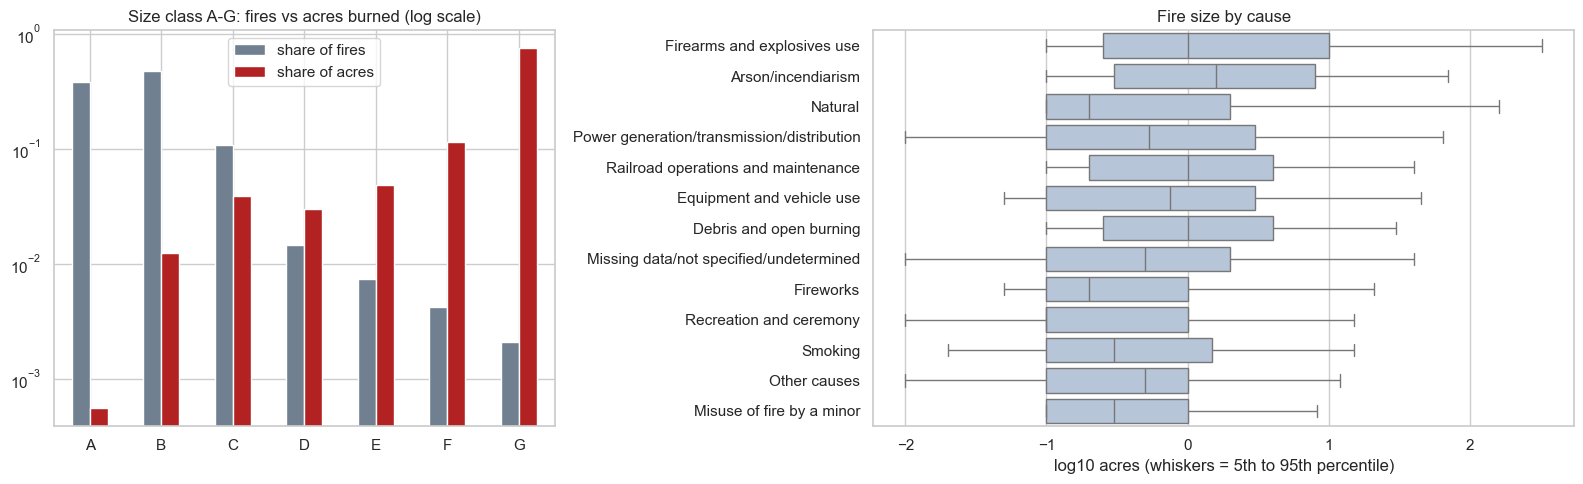

Class G: 0.21% of fires, 75.4% of acres
Lightning: 13.4% of fires, 57.4% of acres


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 1.4]})

fire_share = df['FIRE_SIZE_CLASS'].value_counts(normalize=True).sort_index()
acres = df.groupby('FIRE_SIZE_CLASS', observed=True)['FIRE_SIZE'].sum()
acre_share = acres / acres.sum()
pd.DataFrame({'share of fires': fire_share, 'share of acres': acre_share}).plot.bar(
    ax=axes[0], rot=0, logy=True, color=['slategray', 'firebrick'])
axes[0].set_title('Size class A-G: fires vs acres burned (log scale)')
axes[0].set_xlabel('')

order = df.groupby('NWCG_GENERAL_CAUSE', observed=True)['LOG_SIZE'].quantile(0.9).sort_values(ascending=False).index
sns.boxplot(data=df, x='LOG_SIZE', y='NWCG_GENERAL_CAUSE', order=list(order), showfliers=False,
            whis=(5, 95), color='lightsteelblue', ax=axes[1])
axes[1].set_xlabel('log10 acres (whiskers = 5th to 95th percentile)')
axes[1].set_ylabel('')
axes[1].set_title('Fire size by cause')
plt.tight_layout()
plt.show()

g_fires, g_acres = fire_share['G'], acre_share['G']
natural_acres = df.loc[natural, 'FIRE_SIZE'].sum() / df['FIRE_SIZE'].sum()
print(f'Class G: {g_fires:.2%} of fires, {g_acres:.1%} of acres')
print(f'Lightning: {natural.mean():.1%} of fires, {natural_acres:.1%} of acres')

Fire size is extremely skewed. Class G fires (5,000+ acres) are about 0.2% of fires but about 75% of the area burned, while classes A and B are 86% of fires but barely any area. Lightning causes about 13% of fires but over half of all acres burned.

Because of this skew, I won't predict raw fire size. Size will be used as a log-scaled feature instead.

## 5. Are the problems doable?

### Supervised: predicting cause

Target: cause grouped into 7 classes. Other causes and Missing are left out (see section 1). Train on 1992-2018, test on 2019-2024.

In [9]:
GROUPS = {
    'Natural': 'Natural',
    'Debris and open burning': 'Debris burning',
    'Arson/incendiarism': 'Arson',
    'Equipment and vehicle use': 'Equipment/vehicle',
    'Railroad operations and maintenance': 'Railroad/power lines',
    'Power generation/transmission/distribution': 'Railroad/power lines',
    'Recreation and ceremony': 'Recreation/smoking/fireworks',
    'Smoking': 'Recreation/smoking/fireworks',
    'Fireworks': 'Recreation/smoking/fireworks',
    'Firearms and explosives use': 'Recreation/smoking/fireworks',
    'Misuse of fire by a minor': 'Minor',
}
lab = df[df['CAUSE_KNOWN'] & df['NWCG_GENERAL_CAUSE'].ne('Other causes')].copy()
lab['TARGET'] = lab['NWCG_GENERAL_CAUSE'].astype(str).map(GROUPS)
lab['PERIOD'] = np.where(lab['FIRE_YEAR'] < 2019, 'train 1992-2018', 'test 2019-2024')

share = pd.crosstab(lab['TARGET'], lab['PERIOD'], normalize='columns')[['train 1992-2018', 'test 2019-2024']]
share['fires'] = lab['TARGET'].value_counts()
print(f'{len(lab):,} labelled fires, {(~df.CAUSE_KNOWN).sum():,} fires with no cause')
share.sort_values('fires', ascending=False).round(3)

1,880,198 labelled fires, 689,382 fires with no cause


PERIOD,train 1992-2018,test 2019-2024,fires
TARGET,,,
Debris burning,0.315,0.385,611386
Natural,0.194,0.161,356409
Arson,0.193,0.108,339463
Equipment/vehicle,0.109,0.151,216803
Recreation/smoking/fireworks,0.108,0.118,205625
Railroad/power lines,0.040,0.060,81043
Minor,0.040,0.018,69469


In [10]:
# simple baseline: the most common cause for each 1-degree grid cell and month in the training years
lab['CELL'] = lab['LATITUDE'].round().astype(str) + '_' + lab['LONGITUDE'].round().astype(str)
train, test = lab[lab['FIRE_YEAR'] < 2019], lab[lab['FIRE_YEAR'] >= 2019]


def most_common(keys):
    counts = train.groupby(keys + ['TARGET']).size().reset_index(name='n')
    return counts.sort_values('n').drop_duplicates(keys, keep='last').drop(columns='n')


majority = train['TARGET'].mode().iat[0]
by_cell_month = test[['CELL', 'MONTH']].merge(most_common(['CELL', 'MONTH']), how='left')['TARGET']
by_cell = test[['CELL']].merge(most_common(['CELL']), how='left')['TARGET']
pred = by_cell_month.fillna(by_cell).fillna(majority)
y = test['TARGET'].reset_index(drop=True)
always_majority = pd.Series(majority, index=y.index)

results = pd.DataFrame({
    'accuracy': [accuracy_score(y, always_majority), accuracy_score(y, pred)],
    'macro F1': [f1_score(y, always_majority, average='macro', zero_division=0), f1_score(y, pred, average='macro')],
}, index=['always majority class', 'cell x month lookup']).round(3)
display(results)

scored = pd.DataFrame({'y': y, 'pred': pred, 'year': test['FIRE_YEAR'].to_numpy()})
f1_by_year = {yr: round(f1_score(g['y'], g['pred'], average='macro'), 3) for yr, g in scored.groupby('year')}
print('Lookup macro F1 by test year:', f1_by_year)

,accuracy,macro F1
always majority class,0.385,0.079
cell x month lookup,0.497,0.321


Lookup macro F1 by test year: {2019: 0.333, 2020: 0.303, 2021: 0.337, 2022: 0.322, 2023: 0.31, 2024: 0.313}


There are about 1.9 M labelled fires. The biggest class (Debris burning) is roughly 9 times the smallest (Minor), so class weighting will be needed. The class mix shifts between train and test (arson drops, debris burning rises), which is why I split by year instead of randomly.

A simple lookup by location and month already gets about 0.50 accuracy and 0.32 macro F1 on 2019-2024, and it stays steady across the test years. So there's real signal, and this lookup is the baseline the models need to beat.

### Unsupervised: do fires form clusters?

Features: location, day of year and hour (as sin/cos so Dec 31 sits next to Jan 1), log size, log duration, weekend. The Hopkins statistic checks for cluster structure: about 0.5 means random, close to 1 means clustered.

In [11]:
has_times = df['DISC_HOUR'].notna() & df['CONT_DATE'].notna()
print(f'Fires with discovery time and containment date: {has_times.sum():,} ({has_times.mean():.1%})')
print('Share kept by source system:', has_times.groupby(df['SOURCE_SYSTEM_TYPE'], observed=True).mean().round(2).to_dict())

sample = df[has_times].sample(60_000, random_state=SEED)
doy_angle = 2 * np.pi * sample['DISCOVERY_DOY'] / 365.25
hour_angle = 2 * np.pi * (sample['DISC_HOUR'] + sample['DISC_MIN'] / 60) / 24
X = pd.DataFrame({
    'lat': sample['LATITUDE'], 'lon': sample['LONGITUDE'],
    'doy_sin': np.sin(doy_angle), 'doy_cos': np.cos(doy_angle),
    'hour_sin': np.sin(hour_angle), 'hour_cos': np.cos(hour_angle),
    'log_size': sample['LOG_SIZE'], 'log_duration': np.log1p(sample['DURATION_DAYS']),
    'weekend': (sample['WEEKDAY'] >= 5).astype(float),
})
X = (X - X.mean()) / X.std()


def hopkins(X, m=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    real = nn.kneighbors(X[rng.choice(len(X), m, replace=False)], 2)[0][:, 1]
    fake = nn.kneighbors(rng.uniform(X.min(0), X.max(0), (m, X.shape[1])), 1)[0][:, 0]
    return fake.sum() / (fake.sum() + real.sum())


print(f'Hopkins statistic: {hopkins(X.to_numpy()):.2f}')

Fires with discovery time and containment date: 1,556,638 (58.5%)
Share kept by source system: {'FED': 0.97, 'INTERAGCY': 0.61, 'NONFED': 0.46}


Hopkins statistic: 0.88


The Hopkins statistic is well above 0.5, so there is structure worth clustering. One caveat: only about 58% of fires have both times recorded, and those are mostly federal records, so I'll also try a version without the time features on all fires.

## 6. Research questions

### Supervised: classification
**Can we predict a fire's cause from where, when and on whose land it was reported, and use that to fill in the ~689k fires with no recorded cause?**

- **Target:** cause in 7 groups (Natural, Debris burning, Arson, Equipment/vehicle, Recreation/smoking/fireworks, Railroad/power lines, Minor)
- **Predictors:** latitude/longitude, state, day of year, month, weekday, discovery hour, land owner, reporting agency, fire size, days to containment
- **Not used:** NWCG_CAUSE_CLASSIFICATION and NWCG_CAUSE_AGE_CATEGORY (both reveal the answer), FIRE_NAME (sometimes names the cause), SOURCE_SYSTEM_TYPE (stands in for the year)
- **Validation:** train 1992-2018, test 2019-2024
- **Imbalance:** class weights, compared with resampling
- **Metrics:** macro F1, per-class F1, ROC-AUC, confusion matrix
- **Models:** logistic regression, random forest, LightGBM
- **Baseline:** location + month lookup, macro F1 0.32

### Unsupervised: clustering
**Without using cause labels, what groups of fires come out of location, season, time of day and size? Do those groups match human vs. lightning causes?**

- **Features:** location, day of year and hour (sin/cos), log size, log duration, weekend flag, all standardized
- **Held out for checking the clusters:** cause, land owner, reporting agency
- **Methods:** K-Means / Gaussian mixture, with the number of clusters picked using elbow, silhouette and Davies-Bouldin
- **What I expect to find:** groups like summer-afternoon western lightning fires vs. spring-weekend eastern debris fires, and whether clusters line up with cause even though cause isn't used